# Student Academic Risk Assessment Model

## Purpose
Train a Random Forest classifier to identify student module records with **High**, **Medium**, or **Low** academic risk. This sprint uses the supplied historical learning dataset for training and manually entered student/module inputs for predictions. No LMS results are used.

## Output
- `risk_model.joblib` Ã¢â‚¬â€ trained preprocessing and Random Forest pipeline
- A held-out evaluation report and confusion matrix
- Risk predictions for rows in `../data/manual_risk_inputs.csv`

Run this notebook in VS Code with the Python environment in `python/.venv` selected.

In [ ]:
# ============================================================# IMPORTS AND PATHS# ============================================================from pathlib import Pathimport joblibimport pandas as pdimport matplotlib.pyplot as pltfrom sklearn.ensemble import RandomForestClassifierfrom sklearn.impute import SimpleImputerfrom sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_scorefrom sklearn.model_selection import train_test_splitfrom sklearn.pipeline import PipelineHERE = Path.cwd().resolve()if HERE.name == 'RiskAssessment':    RISK_ASSESSMENT_DIR = HEREelif HERE.name == 'python':    RISK_ASSESSMENT_DIR = HERE / 'RiskAssessment'else:    RISK_ASSESSMENT_DIR = HERE / 'python' / 'RiskAssessment'PYTHON_DIR = RISK_ASSESSMENT_DIR.parentDATA_DIR = PYTHON_DIR / 'data'TRAINING_FILE = DATA_DIR / 'student_academic_risk.csv'MANUAL_FILE = DATA_DIR / 'manual_risk_inputs.csv'MODEL_DIR = RISK_ASSESSMENT_DIR / 'ModelOutput'MODEL_FILE = MODEL_DIR / 'risk_model.joblib'print('Training data:', TRAINING_FILE.resolve())print('Manual inputs:', MANUAL_FILE.resolve())print('Model output:', MODEL_FILE.resolve())

In [ ]:
# ============================================================# LOAD AND REVIEW THE TRAINING DATA# ============================================================if not TRAINING_FILE.exists():    raise FileNotFoundError(f'Missing training CSV: {TRAINING_FILE}')data = pd.read_csv(TRAINING_FILE)print('Rows and columns:', data.shape)print('Risk label counts:')display(data['academic_risk_level'].value_counts(dropna=False))display(data.head())

## Risk labels in the training CSVThis dataset already contains the target column `academic_risk_level`, with `Low`, `Medium`, and `High` labels. The model learns these labels directly; no outcome-to-risk mapping is needed. The file has no module identifier, so module names and each module's current performance indicators are supplied separately in `manual_risk_inputs.csv`.

In [ ]:
# ============================================================# PREPARE FEATURES AND TARGET# ============================================================FEATURES = [    'previous_gpa',    'attendance',    'assignment_score',    'quiz_score',    'study_hours',    'engagement_score',    'late_assignments',    'completed_assignments',    'learning_progress',]RISK_LEVELS = {'low': 'Low', 'medium': 'Medium', 'high': 'High'}missing = [column for column in FEATURES + ['academic_risk_level'] if column not in data.columns]if missing:    raise ValueError(f'Missing required columns: {missing}')data['risk_level'] = data['academic_risk_level'].astype(str).str.strip().str.lower().map(RISK_LEVELS)data = data.dropna(subset=['risk_level']).copy()X, y = data[FEATURES], data['risk_level']print('Training examples:', len(data))display(y.value_counts())

In [ ]:
# ============================================================# BUILD AND TRAIN RANDOM FOREST PIPELINE# ============================================================model = Pipeline([    ('imputer', SimpleImputer(strategy='median')),    ('classifier', RandomForestClassifier(        n_estimators=300,        max_depth=12,        min_samples_leaf=2,        class_weight='balanced_subsample',        random_state=42,        n_jobs=-1,    )),])X_train, X_test, y_train, y_test = train_test_split(    X, y, test_size=0.2, random_state=42, stratify=y)model.fit(X_train, y_train)print('Training complete.')

Accuracy: 0.915
              precision    recall  f1-score   support

        High       0.89      0.89      0.89        47
         Low       0.96      0.97      0.97       100
      Medium       0.85      0.83      0.84        53

    accuracy                           0.92       200
   macro avg       0.90      0.90      0.90       200
weighted avg       0.91      0.92      0.91       200



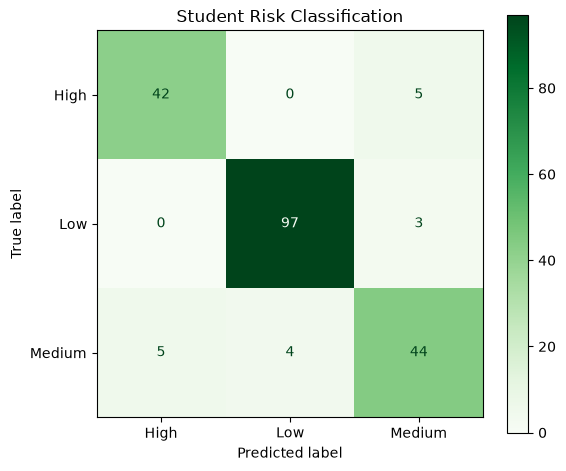

In [38]:
# ============================================================
# EVALUATE HELD-OUT DATA
# ============================================================
predictions = model.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, predictions):.3f}')
print(classification_report(y_test, predictions, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap='Greens')
plt.title('Student Risk Classification')
plt.tight_layout()
plt.show()

## Refit on all labeled rows and saveAfter evaluation, train the final model using all labeled records. The Flask API uses the same feature columns and saves the model under `python/RiskAssessment/ModelOutput/`.

In [ ]:
# ============================================================# TRAIN FINAL MODEL AND SAVE ARTIFACT# ============================================================model.fit(X, y)MODEL_DIR.mkdir(parents=True, exist_ok=True)MODEL_FILE = MODEL_DIR / 'risk_model.joblib'joblib.dump(model, str(MODEL_FILE))if not MODEL_FILE.is_file():    raise OSError(f'Model file was not created: {MODEL_FILE}')print(f'Saved trained model: {MODEL_FILE.resolve()}')print(f'File size: {MODEL_FILE.stat().st_size:,} bytes')

In [ ]:
# ============================================================# SCORE MANUALLY ENTERED STUDENT/MODULE ROWS# ============================================================if not MANUAL_FILE.exists():    raise FileNotFoundError(f'Missing manual input CSV: {MANUAL_FILE}')manual = pd.read_csv(MANUAL_FILE)required = ['student_id', 'student_name', 'module_id', 'module_name'] + FEATURESmissing = [column for column in required if column not in manual.columns]if missing:    raise ValueError(f'Manual input CSV is missing columns: {missing}')if manual.empty:    print('No manual student/module rows to assess.')else:    manual['risk_level'] = model.predict(manual[FEATURES])    manual['confidence'] = model.predict_proba(manual[FEATURES]).max(axis=1)    display_columns = [        'student_id', 'student_name', 'module_id', 'module_name',        'risk_level', 'confidence', 'attendance', 'assignment_score',        'quiz_score', 'engagement_score', 'learning_progress',    ]    print('Predicted risk for each manually entered module:')    display(manual[display_columns])    at_risk = manual[manual['risk_level'].isin(['High', 'Medium'])]    print(f'{len(at_risk)} High/Medium risk module(s) from {len(manual)} manual row(s).')